# Detecção de Fraudes em Transações de Cartão de Crédito

Projeto de Machine Learning para identificação de transações fraudulentas em uma base altamente desbalanceada.

**Objetivo:** construir, comparar e interpretar modelos de classificação, priorizando as métricas adequadas para a classe rara de fraude.

> **Nota:** o dataset não é armazenado neste repositório. Ele é carregado diretamente por uma URL, conforme a orientação do desafio.


## 1. Contexto do problema

Em detecção de fraude, a classe positiva (`Class = 1`) representa uma parcela muito pequena das transações. Por isso, a acurácia pode transmitir uma impressão enganosa de desempenho.

Neste projeto, serão observadas principalmente:

- **Recall:** proporção das fraudes reais que o modelo conseguiu identificar;
- **Precision:** proporção das transações classificadas como fraude que realmente eram fraude;
- **F1-score:** equilíbrio entre precision e recall;
- **ROC-AUC e curva Precision-Recall:** apoio à comparação dos modelos.

O objetivo não é simplesmente maximizar a quantidade total de acertos, mas avaliar o comportamento do modelo diante da classe rara.


## 2. Bibliotecas

Serão utilizadas bibliotecas para manipulação de dados, visualização, Machine Learning e explicabilidade.

Se estiver usando Google Colab e alguma biblioteca não estiver disponível, descomente a célula de instalação.


In [2]:
# Se necessário, execute no Google Colab:
# !pip -q install xgboost shap imbalanced-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42


## 3. Carregamento do dataset

A base utilizada é o conhecido dataset de transações de cartão de crédito, com as colunas `Time`, `Amount`, `Class` e as variáveis transformadas `V1` a `V28`.

**Importante:** se a aula do desafio fornecer uma URL diferente, substitua `DATA_URL` pela URL indicada pela Expert. O arquivo de dados não deve ser enviado ao GitHub.


In [4]:
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(DATA_URL)

print(f"Dimensões da base: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
df.head()


Dimensões da base: 284,807 linhas x 31 colunas


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 4. Exploração inicial

Antes de treinar qualquer modelo, vamos entender a estrutura dos dados e verificar a qualidade da base.


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [7]:
print("Valores ausentes por coluna:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

print(f"\nLinhas duplicadas: {df.duplicated().sum():,}")


Valores ausentes por coluna:


Time    0
V1      0
V2      0
V3      0
V4      0
V5      0
V6      0
V7      0
V8      0
V9      0
dtype: int64


Linhas duplicadas: 1,081


In [8]:
class_counts = df["Class"].value_counts().sort_index()
class_percent = df["Class"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Quantidade": class_counts,
    "Percentual (%)": class_percent.round(4)
}, index=["Normal (0)", "Fraude (1)"])

display(class_summary)


,Quantidade,Percentual (%)
Normal (0),NaN,NaN
Fraude (1),NaN,NaN


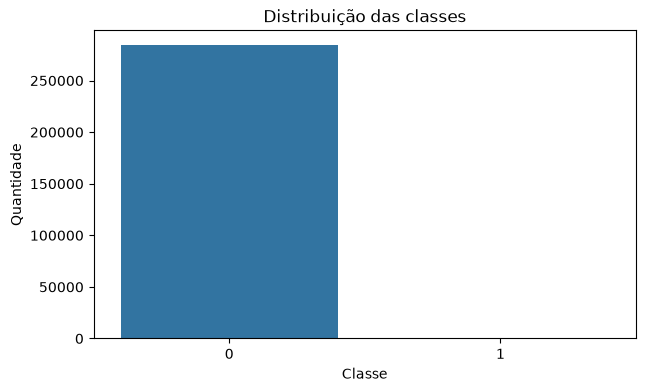

In [9]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Class")
plt.title("Distribuição das classes")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.show()


### Por que a acurácia engana?

Se quase todas as transações são normais, um modelo que classificasse praticamente tudo como `0` poderia apresentar uma acurácia muito alta mesmo sem detectar as fraudes.

Por isso, neste projeto o **recall da classe fraude** terá papel central: perder uma fraude significa produzir um falso negativo, e essa informação é escondida quando observamos apenas a acurácia.


## 5. Preparação dos dados

Será criada uma nova variável `Amount_log`, usando `log1p`, para reduzir a influência da escala assimétrica do valor das transações.

Depois, `Time` e `Amount_log` serão padronizados. As variáveis `V1` a `V28` já são transformadas e serão mantidas.

A divisão será feita em:

- treino: 60%
- validação: 20%
- teste: 20%

O `stratify=y` mantém a proporção de fraude entre as partes.


In [10]:
df_model = df.copy()

df_model["Amount_log"] = np.log1p(df_model["Amount"])

X = df_model.drop(columns="Class")
y = df_model["Class"]

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full,
    test_size=0.25,
    stratify=y_train_full,
    random_state=RANDOM_STATE
)

print("Treino:", X_train.shape)
print("Validação:", X_valid.shape)
print("Teste:", X_test.shape)

print("\nPercentual de fraude:")
print(f"Treino:     {y_train.mean()*100:.4f}%")
print(f"Validação:  {y_valid.mean()*100:.4f}%")
print(f"Teste:      {y_test.mean()*100:.4f}%")


Treino: (170883, 31)
Validação: (56962, 31)
Teste: (56962, 31)

Percentual de fraude:
Treino:     0.1726%
Validação:  0.1738%
Teste:      0.1720%


## 6. Baseline: Regressão Logística

A Regressão Logística será usada como baseline.

Como a classe fraude é rara, será utilizado `class_weight="balanced"` para aumentar a importância dos exemplos da classe minoritária durante o treinamento.

O `StandardScaler` fica dentro do pipeline para que o ajuste da escala seja feito somente com os dados de treinamento.


In [11]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31,)","['Time','V1','V2',...,'V28','Amount','Amount_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 7. Random Forest

O Random Forest será comparado ao baseline. Também será utilizado `class_weight="balanced"` para considerar o desbalanceamento.


In [12]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

## 8. XGBoost

O XGBoost será treinado utilizando `scale_pos_weight`, calculado a partir da proporção entre exemplos normais e fraudulentos no conjunto de treinamento.


In [13]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

print(f"scale_pos_weight = {scale_pos_weight:.2f}")

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)


scale_pos_weight = 578.26


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## 9. Função de avaliação

Primeiro vamos comparar os modelos usando o threshold padrão de `0.50`.

Depois, o threshold será ajustado separadamente para o modelo selecionado, usando o conjunto de validação. O conjunto de teste será preservado para a avaliação final.


In [14]:
def evaluate_model(name, model, X_eval, y_eval, threshold=0.50):
    probabilities = model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return {
        "Modelo": name,
        "Threshold": threshold,
        "Precision": precision_score(y_eval, predictions, zero_division=0),
        "Recall": recall_score(y_eval, predictions, zero_division=0),
        "F1": f1_score(y_eval, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, probabilities),
        "PR-AUC": average_precision_score(y_eval, probabilities)
    }

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

comparison_05 = pd.DataFrame([
    evaluate_model(name, model, X_test, y_test)
    for name, model in models.items()
]).sort_values("Recall", ascending=False)

display(comparison_05.round(4))


,Modelo,Threshold,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.5,0.0610,0.9184,0.1144,0.9731,0.7202
2,XGBoost,0.5,0.8469,0.8469,0.8469,0.9759,0.8697
1,Random Forest,0.5,0.9195,0.8163,0.8649,0.9556,0.8605


## 10. Relatórios de classificação

O relatório permite observar precision, recall e F1 especificamente para a classe `1` (fraude).


In [15]:
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(
        y_test,
        predictions,
        target_names=["Normal", "Fraude"],
        digits=4,
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

      Normal     0.9999    0.9756    0.9876     56864
      Fraude     0.0610    0.9184    0.1144        98

    accuracy                         0.9755     56962
   macro avg     0.5304    0.9470    0.5510     56962
weighted avg     0.9982    0.9755    0.9861     56962

Random Forest
              precision    recall  f1-score   support

      Normal     0.9997    0.9999    0.9998     56864
      Fraude     0.9195    0.8163    0.8649        98

    accuracy                         0.9996     56962
   macro avg     0.9596    0.9081    0.9323     56962
weighted avg     0.9995    0.9996    0.9995     56962

XGBoost
              precision    recall  f1-score   support

      Normal     0.9997    0.9997    0.9997     56864
      Fraude     0.8469    0.8469    0.8469        98

    accuracy                         0.9995     56962
   macro avg     0.9233    0.9233    0.9233     56962
weighted avg     0.9995    0.999

## 11. Curva ROC

A curva ROC mostra a relação entre taxa de verdadeiros positivos e taxa de falsos positivos em diferentes thresholds.

Ela será usada como uma visão complementar. Em problemas extremamente desbalanceados, a curva Precision-Recall é especialmente importante.


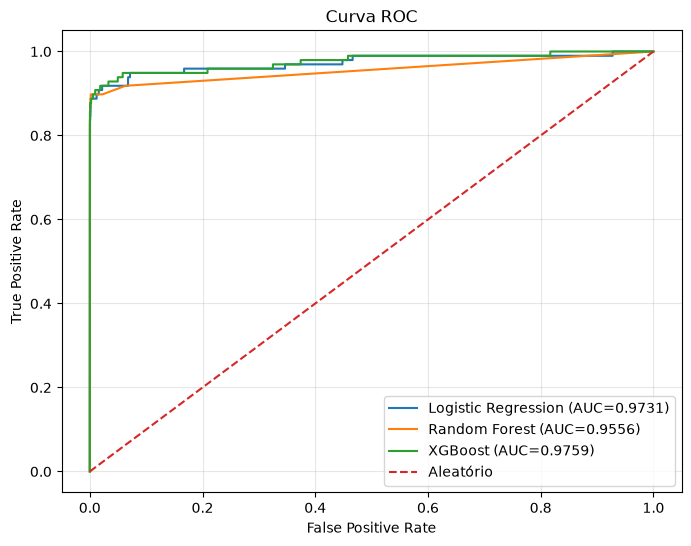

In [16]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Aleatório")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 12. Curva Precision-Recall

Como a fraude é uma classe rara, a relação entre precision e recall ajuda a visualizar melhor o comportamento do modelo diante da classe positiva.


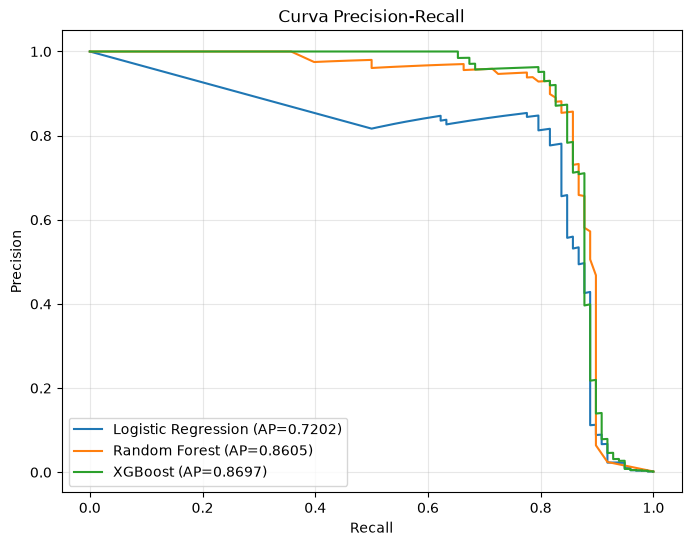

In [17]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    pr_auc = average_precision_score(y_test, probabilities)
    plt.plot(recall, precision, label=f"{name} (AP={pr_auc:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 13. Escolha do modelo para ajuste de threshold

Para demonstrar o ajuste do limiar, vamos utilizar o XGBoost. A escolha deve ser justificada pelos resultados observados na tabela anterior, e não por uma suposição prévia.

O threshold será escolhido **usando apenas o conjunto de validação**.


In [18]:
validation_probabilities = xgb_model.predict_proba(X_valid)[:, 1]

threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.05):
    predictions = (validation_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_valid, predictions, zero_division=0),
        "Recall": recall_score(y_valid, predictions, zero_division=0),
        "F1": f1_score(y_valid, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1
0,0.05,0.5000,0.8384,0.6264
1,0.10,0.6231,0.8182,0.7074
2,0.15,0.7182,0.7980,0.7560
3,0.20,0.7745,0.7980,0.7861
4,0.25,0.8061,0.7980,0.8020
5,0.30,0.8316,0.7980,0.8144
6,0.35,0.8298,0.7879,0.8083
7,0.40,0.8280,0.7778,0.8021
8,0.45,0.8370,0.7778,0.8063
9,0.50,0.8556,0.7778,0.8148


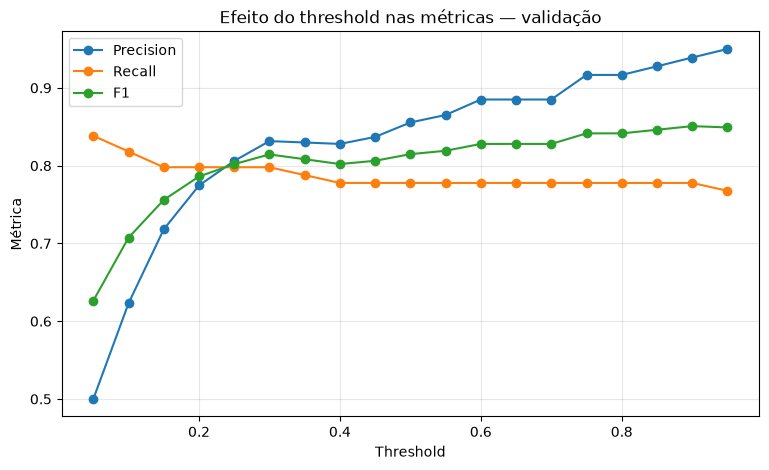

In [19]:
plt.figure(figsize=(9, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1"], marker="o", label="F1")

plt.xlabel("Threshold")
plt.ylabel("Métrica")
plt.title("Efeito do threshold nas métricas — validação")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Critério adotado

Neste projeto, o threshold será escolhido priorizando o recall da fraude, mas observando também precision e F1. Isso evita tratar um recall alto isoladamente como sinônimo de um modelo adequado.

O valor abaixo seleciona, entre os thresholds testados, aquele com maior F1. Depois podemos alterar esse critério se a análise do projeto indicar que reduzir falsos negativos é mais importante.


In [20]:
best_row = threshold_df.loc[threshold_df["F1"].idxmax()]
selected_threshold = float(best_row["Threshold"])

print(f"Threshold selecionado pela validação: {selected_threshold:.2f}")
display(best_row.to_frame().T.round(4))


Threshold selecionado pela validação: 0.90


,Threshold,Precision,Recall,F1
17,0.9,0.939,0.7778,0.8508


## 14. Avaliação final com o threshold escolhido

Agora aplicamos o threshold definido no conjunto de validação ao conjunto de teste, que não participou dessa escolha.


In [21]:
test_probabilities = xgb_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype(int)

final_metrics = {
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities)
}

display(pd.DataFrame([final_metrics]).round(4))

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Normal", "Fraude"],
    digits=4,
    zero_division=0
))


,Precision,Recall,F1,ROC-AUC,PR-AUC
0,0.9302,0.8163,0.8696,0.9759,0.8697


              precision    recall  f1-score   support

      Normal     0.9997    0.9999    0.9998     56864
      Fraude     0.9302    0.8163    0.8696        98

    accuracy                         0.9996     56962
   macro avg     0.9650    0.9081    0.9347     56962
weighted avg     0.9996    0.9996    0.9996     56962



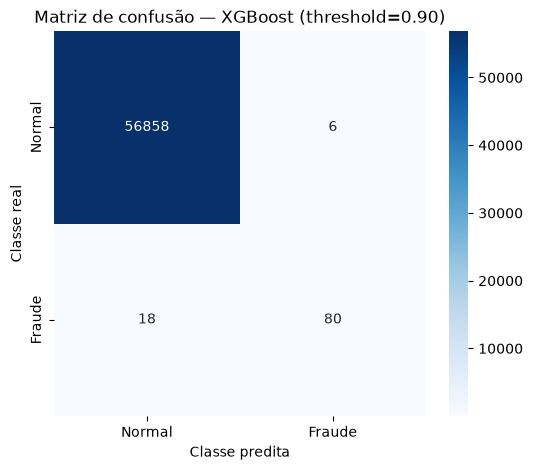

In [22]:
cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraude"],
    yticklabels=["Normal", "Fraude"]
)
plt.xlabel("Classe predita")
plt.ylabel("Classe real")
plt.title(f"Matriz de confusão — XGBoost (threshold={selected_threshold:.2f})")
plt.show()


## 15. Importância das variáveis — Random Forest

A importância das variáveis ajuda a identificar quais atributos foram mais utilizados pelo Random Forest nas decisões do modelo.

Como `V1` a `V28` são componentes transformadas por PCA, a importância de uma variável não deve ser interpretada como se ela representasse diretamente uma característica original do cliente ou da compra.


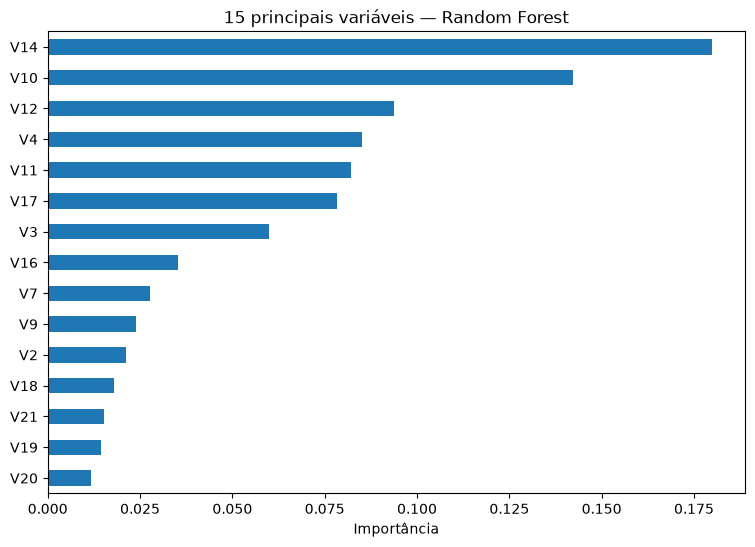

,Importância
V14,0.179876
V10,0.142305
V12,0.093703
V4,0.085103
V11,0.082035
V17,0.078264
V3,0.059811
V16,0.035384
V7,0.027795
V9,0.023814


In [23]:
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
rf_importance.head(15).sort_values().plot(kind="barh")
plt.xlabel("Importância")
plt.title("15 principais variáveis — Random Forest")
plt.show()

display(rf_importance.head(15).to_frame("Importância").round(6))


## 16. Explicabilidade com SHAP

O SHAP permite observar como as variáveis contribuíram para as previsões do modelo.

Para evitar uma visualização excessivamente pesada, será utilizada uma amostra das transações de teste.


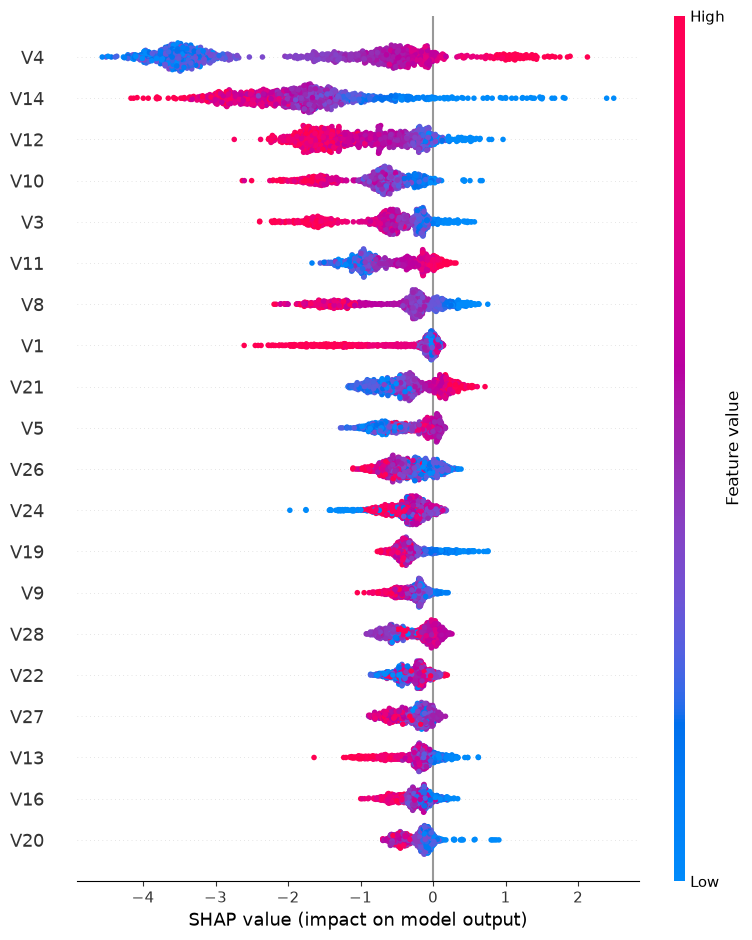

In [24]:
X_shap = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=RANDOM_STATE
)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap)

shap.summary_plot(
    shap_values,
    X_shap,
    show=True
)


### Interpretação do SHAP

No gráfico, valores SHAP positivos indicam contribuição para aumentar a saída do modelo em direção à classe fraude, enquanto valores negativos indicam contribuição na direção oposta.

A interpretação deve ser feita com cuidado: as variáveis `V1` a `V28` são transformações PCA e, portanto, não possuem uma interpretação de negócio direta fornecida pela base.


## 17. Teste opcional de oversampling e undersampling

Esta seção pode ser utilizada como extensão do projeto para comparar estratégias de balanceamento.

Ela não substitui a abordagem principal com pesos de classe. O objetivo é testar empiricamente se uma técnica de reamostragem melhora as métricas relevantes.

> Se utilizar esta seção, instale `imbalanced-learn` e registre no README o resultado observado.


In [25]:
# Opcional:
# from imblearn.over_sampling import RandomOverSampler
# from imblearn.under_sampling import RandomUnderSampler
#
# oversampler = RandomOverSampler(random_state=RANDOM_STATE)
# X_train_over, y_train_over = oversampler.fit_resample(X_train, y_train)
#
# undersampler = RandomUnderSampler(random_state=RANDOM_STATE)
# X_train_under, y_train_under = undersampler.fit_resample(X_train, y_train)
#
# print("Original:", y_train.value_counts().to_dict())
# print("Oversampling:", y_train_over.value_counts().to_dict())
# print("Undersampling:", y_train_under.value_counts().to_dict())


## 18. Conclusões

### Principais aprendizados

- A acurácia isolada não é suficiente em uma base extremamente desbalanceada.
- Recall, precision e F1 permitem observar melhor o comportamento sobre a classe fraude.
- O tratamento do desbalanceamento pode ser feito por pesos de classe e também por técnicas de reamostragem.
- O threshold influencia diretamente o equilíbrio entre detectar mais fraudes e gerar mais falsos positivos.
- SHAP ajuda a explicar quais variáveis contribuíram para as previsões do modelo.

### O que foi diferente em relação à aula

Preencher após a execução do projeto. Exemplos do que pode ser documentado:

1. divisão em treino, validação e teste para separar a escolha do threshold da avaliação final;
2. comparação estruturada entre Regressão Logística, Random Forest e XGBoost;
3. análise sistemática de thresholds;
4. utilização de uma amostra para a explicação SHAP;
5. testes adicionais de oversampling e/ou undersampling, caso realizados.
